# Nhận dạng hoạt động và ước lượng nhịp tim trên PPG-DaLiA

**Mạng 1D-CNN đa nhiệm dùng chung bộ trích xuất đặc trưng**  
Đặng Minh Tài · MSSV 23110148 · IOT-01CLC

Notebook thực hiện B0 (đỉnh phổ), B1 (HR), B2 (HAR) và M1 (HR + HAR), đánh giá trên năm lượt chia theo người. Các bảng và hình là kết quả chạy với `SMOKE=False`.

**Chạy trên Colab:** chọn GPU, chạy các cell theo thứ tự và cấp quyền Google Drive. Dữ liệu tự tải từ UCI vào `/content/PPG_FieldStudy`; kết quả và checkpoint lưu tại `MyDrive/M1_results`. `tqdm` vẫn hiển thị tiến độ khi chạy lại. Checkpoint sau mỗi epoch cho phép tiếp tục sau khi ngắt.

**Gói kết quả để nộp:** `M1_results.zip` giữ CSV, JSON và hình; đã bỏ `.npz` và `.pt`. Gói này đủ để đối chiếu số liệu nhưng không chứa trọng số để suy luận hoặc tiếp tục huấn luyện. Chạy lại sẽ dùng checkpoint trên Drive nếu còn; nếu thiếu checkpoint, mô hình tương ứng được huấn luyện lại.

[Nguồn dữ liệu UCI](https://archive.ics.uci.edu/dataset/495/ppg+dalia) · [README chính thức](https://archive.ics.uci.edu/ml/machine-learning-databases/00495/readme.pdf)


In [ ]:
# Colab T4 thường đã có các thư viện dưới đây. Nếu thiếu: %pip install -q tqdm requests numpy pandas scipy scikit-learn matplotlib torch
import os, sys, json, pickle, time, random, hashlib, platform, warnings, io
from pathlib import Path
import numpy as np, pandas as pd, scipy, torch, torch.nn as nn
import torch.nn.functional as F
from scipy.signal import butter, sosfiltfilt, resample_poly
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
print({'python':sys.version.split()[0], 'torch':torch.__version__, 'scipy':scipy.__version__, 'cuda':torch.version.cuda, 'device':torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})


{'python': '3.13.15', 'torch': '2.11.0+cu128', 'scipy': '1.16.3', 'cuda': '12.8', 'device': 'Tesla T4'}


## 1. Dữ liệu và cấu hình thí nghiệm

Đầu vào gồm BVP 64 Hz và ACC ba trục 32 Hz ở cổ tay. Nhãn HR có sẵn được tạo từ ECG trên cửa sổ 8 giây, bước 2 giây; ECG không được đưa vào mô hình. Tám mã hoạt động 1–8 được ánh xạ sang lớp 0–7, loại mã chuyển tiếp 0.

Cell dưới thiết lập năm lượt chia cố định: 9 người Train, 3 người Validation, 3 người Test. Số nhãn HR và độ dài tín hiệu được kiểm tra trước tiền xử lý.


In [ ]:
BASE_DIR = Path('/content') if Path('/content').is_dir() else Path.cwd()
DATA_ROOT = BASE_DIR/'PPG_FieldStudy'
SAVE_RESULTS_TO_DRIVE = True  # bắt buộc để tự khôi phục qua các phiên Colab
if SAVE_RESULTS_TO_DRIVE:
    if not Path('/content').is_dir(): raise RuntimeError('Drive mount chỉ hỗ trợ trên Google Colab.')
    from google.colab import drive
    drive.mount('/content/drive')
OUT = (Path('/content/drive/MyDrive/M1_results') if SAVE_RESULTS_TO_DRIVE else BASE_DIR/'M1_results')
OUT.mkdir(parents=True, exist_ok=True)
HR_T0_SECONDS = 0.0
ACTIVITY_CODE_TO_CLASS = {1:0, 2:1, 3:2, 4:3, 5:4, 6:5, 7:6, 8:7}
CLASS_NAMES = ['Sitting','Stairs','Table soccer','Cycling','Driving','Lunch','Walking','Working']
SEED, BATCH, MAX_EPOCHS, PATIENCE = 42, 64, 100, 10
LAMBDAS = (0.1, 1.0, 10.0)
SMOKE = False  # True: thử 2 epoch/mô hình; kết quả không dùng để báo cáo
EXPERIMENT_VERSION = 'M1_core_2026_09_29_v3'  # giữ tương thích checkpoint hoàn chỉnh bản cũ
SESSION_TRAIN_MINUTES = 300  # dừng sạch ở cuối epoch sau ~5 giờ; None để chạy đến khi Colab ngắt
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
GROUPS = [[1,2,3],[4,5,6],[7,8,9],[10,11,12],[13,14,15]]
SPLITS = []
for t in range(5):
    tr = [s for g in range(5) if g not in (t,(t+1)%5) for s in GROUPS[g]]
    va, te = GROUPS[(t+1)%5], GROUPS[t]
    SPLITS.append((tr,va,te))
assert len({s for _,_,te in SPLITS for s in te})==15
assert all(len(tr)==9 and len(va)==3 and len(te)==3 and not (set(tr)&set(va)|set(tr)&set(te)|set(va)&set(te)) for tr,va,te in SPLITS)
pd.DataFrame([dict(fold=i+1,train=str(tr),validation=str(va),test=str(te)) for i,(tr,va,te) in enumerate(SPLITS)])


Mounted at /content/drive


,fold,train,validation,test
0,1,"[7, 8, 9, 10, 11, 12, 13, 14, 15]","[4, 5, 6]","[1, 2, 3]"
1,2,"[1, 2, 3, 10, 11, 12, 13, 14, 15]","[7, 8, 9]","[4, 5, 6]"
2,3,"[1, 2, 3, 4, 5, 6, 13, 14, 15]","[10, 11, 12]","[7, 8, 9]"
3,4,"[1, 2, 3, 4, 5, 6, 7, 8, 9]","[13, 14, 15]","[10, 11, 12]"
4,5,"[4, 5, 6, 7, 8, 9, 10, 11, 12]","[1, 2, 3]","[13, 14, 15]"


### Tiếp nhận checkpoint có sẵn

Cell dưới chép các file còn thiếu từ thư mục kết quả cục bộ lên Drive, giữ nguyên file đã có. Nếu checkpoint đã nằm trong `MyDrive/M1_results`, không cần sao lưu thêm.


In [ ]:
import shutil
LOCAL_OLD_RESULTS = BASE_DIR/'M1_results'
if SAVE_RESULTS_TO_DRIVE and LOCAL_OLD_RESULTS.is_dir() and LOCAL_OLD_RESULTS.resolve()!=OUT.resolve():
    candidates=[p for p in LOCAL_OLD_RESULTS.rglob('*') if p.is_file()]
    copied=0
    for old in tqdm(candidates,desc='Sao lưu phần cũ',unit='file'):
        target=OUT/old.relative_to(LOCAL_OLD_RESULTS)
        if target.exists(): continue
        target.parent.mkdir(parents=True,exist_ok=True)
        shutil.copy2(old,target)
        copied+=1
    print(f'Đã copy {copied} file còn thiếu; không ghi đè file trên Drive.')
print('Thư mục kết quả:',OUT)
print('Mô hình hoàn chỉnh có sẵn:',len(list(OUT.glob('fold*.pt'))))


Thư mục kết quả: /content/drive/MyDrive/M1_results
Mô hình hoàn chỉnh có sẵn: 17


### Tải và kiểm tra dữ liệu UCI

Notebook tải ZIP chính thức, hỗ trợ tải tiếp, giải nén 15 file `S*.pkl` và lấy README. ZIP tạm được xóa sau khi giải nén; dữ liệu gốc vẫn giữ trong runtime. Khi đã đủ dữ liệu, bước tải được bỏ qua. Cell kiểm tra tiếp theo ghi kích thước, mã hoạt động và SHA256 để nhận diện phiên bản dữ liệu.


In [ ]:
import re, shutil, zipfile, requests

UCI_ZIP_URL = 'https://archive.ics.uci.edu/static/public/495/ppg%2Bdalia.zip'
README_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00495/readme.pdf'
ARCHIVE_DIR = BASE_DIR/'ppg_dalia_download'
ARCHIVE_DIR.mkdir(parents=True, exist_ok=True)
OUTER_ZIP = ARCHIVE_DIR/'ppg_dalia_uci.zip'
INNER_ZIP = ARCHIVE_DIR/'data.zip'

def complete_data(root):
    return all((root/f'S{s}'/f'S{s}.pkl').is_file() and (root/f'S{s}'/f'S{s}.pkl').stat().st_size>0 for s in range(1,16))

def copy_progress(reader, writer, total, description):
    with tqdm(total=total, unit='B', unit_scale=True, desc=description, leave=False) as bar:
        while chunk := reader.read(1024*1024):
            writer.write(chunk); bar.update(len(chunk))

def download_resumable(url, target, attempts=5):
    # Tải tiếp qua HTTP Range; nếu server trả 200 thì ghi lại từ đầu, tránh nối file sai.
    for attempt in range(1,attempts+1):
        offset=target.stat().st_size if target.exists() else 0
        headers={'Range':f'bytes={offset}-'} if offset else {}
        try:
            with requests.get(url,stream=True,timeout=(20,120),headers=headers) as response:
                if response.status_code==416 and zipfile.is_zipfile(target): return
                response.raise_for_status()
                resume=offset>0 and response.status_code==206
                if resume and not response.headers.get('Content-Range','').startswith(f'bytes {offset}-'):
                    raise RuntimeError('Máy chủ trả Content-Range không khớp file tải dở.')
                mode='ab' if resume else 'wb'
                total=int(response.headers.get('Content-Length',0)) or None
                if total is not None: total+=offset if resume else 0
                with target.open(mode) as out, tqdm(total=total,initial=offset if resume else 0,
                        unit='B',unit_scale=True,desc=f'Tải UCI ({attempt}/{attempts})') as bar:
                    for chunk in response.iter_content(chunk_size=4*1024*1024):
                        if chunk: out.write(chunk);bar.update(len(chunk))
            if not zipfile.is_zipfile(target): raise zipfile.BadZipFile('Tệp tải xong không có cấu trúc ZIP')
            return
        except (requests.RequestException, zipfile.BadZipFile) as err:
            if attempt==attempts: raise RuntimeError(f'Tải UCI thất bại sau {attempts} lần: {err}') from err
            print(f'Mạng ngắt hoặc ZIP chưa đủ ({err}); thử tiếp từ byte {target.stat().st_size if target.exists() else 0}.')
            time.sleep(min(2*attempt,10))

def extract_pickles(inner_path, root):
    # Đích do notebook tự tạo; không dùng đường dẫn từ ZIP để tránh ghi ra ngoài root.
    with zipfile.ZipFile(inner_path) as z:
        found={}
        for member in z.infolist():
            m=re.search(r'(?:^|/)S(1[0-5]|[1-9])/S\1\.pkl$',member.filename)
            if m:
                s=int(m.group(1))
                if s in found: raise RuntimeError(f'ZIP chứa hai bản S{s}.pkl.')
                found[s]=member
        if set(found)!=set(range(1,16)):
            raise RuntimeError(f'ZIP thiếu pickle: {sorted(set(range(1,16))-set(found))}. Tên đầu: {z.namelist()[:10]}')
        root.mkdir(parents=True,exist_ok=True)
        for s in tqdm(range(1,16),desc='Giải nén subject',unit='người'):
            dst=root/f'S{s}'/f'S{s}.pkl';dst.parent.mkdir(exist_ok=True)
            if dst.is_file() and dst.stat().st_size==found[s].file_size: continue
            tmp=dst.with_suffix('.pkl.part')
            with z.open(found[s]) as reader, tmp.open('wb') as writer:
                copy_progress(reader,writer,found[s].file_size,f'S{s}.pkl')
            if tmp.stat().st_size!=found[s].file_size: raise IOError(f'S{s} chưa giải nén đủ.')
            tmp.replace(dst)

if not complete_data(DATA_ROOT):
    if not INNER_ZIP.exists():
        if not zipfile.is_zipfile(OUTER_ZIP):
            free_gb=shutil.disk_usage(BASE_DIR).free/1e9
            if free_gb<7: raise RuntimeError(f'Chỉ còn {free_gb:.1f} GB; cần khoảng 7 GB ổ trống trước khi tải.')
            download_resumable(UCI_ZIP_URL,OUTER_ZIP)
        with zipfile.ZipFile(OUTER_ZIP) as z:
            candidates=[m for m in z.infolist() if m.filename.lower().endswith('/data.zip') or m.filename.lower()=='data.zip']
            if len(candidates)!=1: raise RuntimeError(f'ZIP ngoài cần đúng một data.zip; thấy {z.namelist()[:15]}')
            with z.open(candidates[0]) as reader, INNER_ZIP.with_suffix('.zip.part').open('wb') as writer:
                copy_progress(reader,writer,candidates[0].file_size,'Tách data.zip')
            INNER_ZIP.with_suffix('.zip.part').replace(INNER_ZIP)
            for item in z.infolist():
                if item.filename.lower().endswith('readme.pdf'):
                    DATA_ROOT.mkdir(parents=True,exist_ok=True)
                    with z.open(item) as reader, (DATA_ROOT/'UCI_readme.pdf').open('wb') as writer:
                        shutil.copyfileobj(reader,writer)
                    break
        OUTER_ZIP.unlink()  # lấy lại ổ trống trước khi giải nén subject
    if not zipfile.is_zipfile(INNER_ZIP):
        raise RuntimeError(f'data.zip không hợp lệ: {INNER_ZIP}. Xóa file này rồi chạy lại.')
    extract_pickles(INNER_ZIP,DATA_ROOT)
    if not complete_data(DATA_ROOT): raise RuntimeError('Chưa đủ 15 pickle sau giải nén.')
    INNER_ZIP.unlink()
# README chỉ 799 kB, tải bổ sung nếu bản ZIP không kèm theo.
if not (DATA_ROOT/'UCI_readme.pdf').exists():
    r=requests.get(README_URL,timeout=(20,120));r.raise_for_status()
    (DATA_ROOT/'UCI_readme.pdf').write_bytes(r.content)
print('Sẵn sàng:',DATA_ROOT,'| 15/15 subject | README:',DATA_ROOT/'UCI_readme.pdf')


Sẵn sàng: /content/PPG_FieldStudy | 15/15 subject | README: /content/PPG_FieldStudy/UCI_readme.pdf


In [ ]:
def subject_path(s):
    candidates = [DATA_ROOT/f'S{s}'/f'S{s}.pkl', DATA_ROOT/f'S{s}.pkl']
    return next((p for p in candidates if p.is_file()), candidates[0])

def load_subject(s):
    p=subject_path(s)
    if not p.exists(): raise FileNotFoundError(f'Thiếu {p}; tải và giải nén data.zip của UCI trước.')
    with p.open('rb') as f: d=pickle.load(f, encoding='latin1')
    bvp=np.asarray(d['signal']['wrist']['BVP']).reshape(-1)
    acc=np.asarray(d['signal']['wrist']['ACC'])
    activity=np.asarray(d['activity']).reshape(-1)
    hr=np.asarray(d['label']).reshape(-1)
    if acc.ndim!=2 or acc.shape[1]!=3: raise ValueError(f'S{s}: ACC phải là (T,3), có {acc.shape}')
    return bvp,acc,activity,hr

missing=[str(subject_path(s)) for s in range(1,16) if not subject_path(s).exists()]
if missing: raise FileNotFoundError('Thiếu pickle; xem DATA_ROOT. Ví dụ: '+missing[0])
audit=[]
for s in tqdm(range(1,16),desc='Kiểm tra cấu trúc',unit='người'):
    bvp,acc,act,hr=load_subject(s)
    duration=len(bvp)/64
    expected=int(np.floor((duration-8-HR_T0_SECONDS)/2))+1
    audit.append(dict(subject=f'S{s}',bvp=len(bvp),acc=len(acc),activity=len(act),hr=len(hr),seconds=duration, expected_hr=expected, codes=np.unique(act).tolist()))
audit_df=pd.DataFrame(audit)
display(audit_df)
assert all(abs(row['bvp']/64-row['acc']/32)<2 for row in audit), 'Lệch thời lượng BVP/ACC; kiểm tra README.'
assert all(abs(row['bvp']/64-row['activity']/4)<2 for row in audit), 'Lệch thời lượng nhãn hoạt động.'
assert all(row['expected_hr']==row['hr'] for row in audit), 'Số HR không khớp cửa sổ [t0+2i,t0+2i+8); xác minh mốc nhãn theo README.'
observed={int(v) for row in audit for v in row['codes'] if np.isfinite(v) and float(v).is_integer()}
print('Mã hoạt động quan sát:',sorted(observed),'| mã giữ:',ACTIVITY_CODE_TO_CLASS)
assert set(ACTIVITY_CODE_TO_CLASS)==set(range(1,9)) and set(ACTIVITY_CODE_TO_CLASS.values())==set(range(8))
assert observed.issubset(set(range(9))), f'Gặp mã không có trong README UCI: {observed-set(range(9))}'
assert set(ACTIVITY_CODE_TO_CLASS).issubset(observed), 'Thiếu mã hoạt động dự kiến trên toàn tập; kiểm tra bản dữ liệu.'
audit_df.to_csv(OUT/'raw_data_audit.csv',index=False)
readme_bytes=(DATA_ROOT/'UCI_readme.pdf').read_bytes()
pickle_hashes={}
for i in tqdm(range(1,16),desc='Kiểm tra SHA256 dữ liệu',unit='người'):
    h=hashlib.sha256()
    with subject_path(i).open('rb') as stream:
        while chunk := stream.read(4*1024*1024): h.update(chunk)
    pickle_hashes[f'S{i}']=h.hexdigest()

source_manifest=dict(url=UCI_ZIP_URL,readme_url=README_URL,
    readme_sha256=hashlib.sha256(readme_bytes).hexdigest(),
    pickle_sizes={f'S{i}':subject_path(i).stat().st_size for i in range(1,16)},
    pickle_sha256=pickle_hashes,
    python=sys.version.split()[0],torch=torch.__version__,scipy=scipy.__version__,
    cuda=torch.version.cuda,device=str(DEVICE),seed=SEED)
(OUT/'source_environment.json').write_text(json.dumps(source_manifest,indent=2),encoding='utf-8')



,subject,bvp,acc,activity,hr,seconds,expected_hr,codes
0,S1,589568,294784,36848,4603,9212.0,4603,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]"
1,S2,525120,262560,32820,4099,8205.0,4099,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]"
2,S3,559424,279712,34964,4367,8741.0,4367,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]"
3,S4,585600,292800,36600,4572,9150.0,4572,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]"
4,S5,595520,297760,37220,4649,9305.0,4649,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]"
5,S6,336000,168000,21000,2622,5250.0,2622,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0]"
6,S7,597952,298976,37372,4668,9343.0,4668,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]"
7,S8,517120,258560,32320,4037,8080.0,4037,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]"
8,S9,547840,273920,34240,4277,8560.0,4277,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]"
9,S10,681472,340736,42592,5321,10648.0,5321,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]"


Mã hoạt động quan sát: [0, 1, 2, 3, 4, 5, 6, 7, 8] | mã giữ: {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6, 8: 7}


1940

## 2. Tiền xử lý và tạo cửa sổ

BVP được lọc Butterworth (`N=4`, dải 0,5–8 Hz, dạng SOS) bằng `sosfiltfilt` trên bản ghi liên tục. ACC được lấy mẫu lại lên 64 Hz. Mỗi đầu vào có kích thước **4 × 512**.

Chỉ giữ cửa sổ có HR hợp lệ và 32 nhãn hoạt động cùng thuộc một lớp. Các đoạn bị loại không được nối lại. `window_audit.csv` lưu trạng thái từng cửa sổ; cache phụ thuộc cấu hình và SHA256 dữ liệu.


In [ ]:
CACHE = OUT/'cache_64hz'
CACHE.mkdir(exist_ok=True)
PREP_CONFIG=dict(dataset_sha256=pickle_hashes, hr_t0=HR_T0_SECONDS, mapping=ACTIVITY_CODE_TO_CLASS, fs_bvp=64, fs_acc=32, fs_activity=4, window=8, stride=2, ppg_band=[0.5,8], butter_N=4)
PREP_HASH=hashlib.sha256(json.dumps(PREP_CONFIG,sort_keys=True).encode()).hexdigest()[:12]

def prepare_subject(s, force=False):
    cache=CACHE/f'S{s}_{PREP_HASH}.npz'; profile=CACHE/f'S{s}_{PREP_HASH}_audit.csv'
    if cache.exists() and profile.exists() and not force:
        with np.load(cache) as z: return {k:z[k] for k in z.files}, pd.read_csv(profile)
    bvp,acc,act,hr=load_subject(s)
    if not (np.isfinite(bvp).all() and np.isfinite(acc).all()): raise ValueError(f'S{s}: tín hiệu chứa NaN/Inf; cần ghi nhận lỗi dữ liệu.')
    sos=butter(4,[0.5,8],btype='bandpass',fs=64,output='sos')
    ppg=sosfiltfilt(sos,bvp).astype(np.float32)
    acc64=resample_poly(acc,2,1,axis=0).astype(np.float32)
    x_list=[]; ids=[]; y_hr=[]; y_act=[]; rows=[]
    for i,y in enumerate(hr):
        t=HR_T0_SECONDS+2*i; e=t+8
        # exact integer sample boundaries for this 64/4 Hz grid
        a64=round(t*64); b64=a64+512; a4=round(t*4); b4=a4+32
        reason='kept'; c=-1
        if not np.isfinite(y): reason='invalid_hr'
        elif a64<0 or b64>len(ppg) or b64>len(acc64) or a4<0 or b4>len(act): reason='out_of_bounds'
        else:
            codes=act[a4:b4]
            if not np.isfinite(codes).all() or not np.all(codes==codes[0]): reason='transition_or_mixed'
            elif float(codes[0]) not in ACTIVITY_CODE_TO_CLASS: reason='out_of_scope'
            else: c=ACTIVITY_CODE_TO_CLASS[int(codes[0])]
        if reason=='kept':
            x=np.concatenate([ppg[a64:b64,None],acc64[a64:b64]],axis=1).T
            if not np.isfinite(x).all(): reason='invalid_signal'
            else:
                x_list.append(x); ids.append(i); y_hr.append(float(y)); y_act.append(c)
        rows.append((f'S{s}',i,t,e,float(y),c,reason))
    meta=pd.DataFrame(rows,columns=['subject_id','window_index','start_s','end_s','hr_bpm','class_id','status'])
    assert len(ids)==len(set(ids))
    X=np.stack(x_list).astype(np.float32) if x_list else np.empty((0,4,512),np.float32)
    data=dict(X=X, idx=np.array(ids,np.int32), hr=np.array(y_hr,np.float32), cls=np.array(y_act,np.int64))
    np.savez(cache,**data); meta.to_csv(profile,index=False)
    return data,meta

prepared={}; profiles=[]
for s in tqdm(range(1,16),desc='Lọc và cắt cửa sổ',unit='người'):
    prepared[s],m=prepare_subject(s)
    profiles.append(m)
profile=pd.concat(profiles,ignore_index=True)
counts=profile.groupby(['subject_id','status']).size().unstack(fill_value=0)
counts['total']=counts.sum(axis=1); counts['keep_rate']=counts.get('kept',0)/counts['total']
display(counts)
display(profile.loc[profile.status=='kept'].pivot_table(index='subject_id',columns='class_id',values='window_index',aggfunc='count',fill_value=0))
assert all(len(prepared[s]['X'])>0 and prepared[s]['X'].shape[1:]==(4,512) for s in range(1,16))
profile.to_csv(OUT/'window_audit.csv',index=False)
(OUT/'preprocess_config.json').write_text(json.dumps(PREP_CONFIG,indent=2),encoding='utf-8')


status,kept,out_of_scope,transition_or_mixed,total,keep_rate
subject_id,,,,,
S1,3438,1113,52,4603,0.746904
S10,3526,1744,51,5321,0.662657
S11,3474,986,61,4521,0.768414
S12,2928,966,60,3954,0.740516
S13,3342,1163,60,4565,0.732092
S14,3171,1254,51,4476,0.708445
S15,2907,998,61,3966,0.732980
S2,2807,1232,60,4099,0.684801
S3,3330,977,60,4367,0.762537


class_id,0,1,2,3,4,5,6,7
subject_id,,,,,,,,
S1,347,140,169,203,441,1174,373,591
S10,296,230,149,241,465,1038,538,569
S11,296,224,158,241,426,1200,323,606
S12,297,238,136,236,441,726,261,593
S13,298,244,141,245,445,1010,351,608
S14,301,225,159,248,473,862,304,599
S15,302,205,173,199,389,716,325,598
S2,296,129,148,190,456,606,341,641
S3,296,214,142,185,451,1076,365,601


1470

## 3. Chuẩn hóa từ Train và đối chuẩn B0

Thống kê bốn kênh được tính trên hợp các mẫu liên tục thuộc cửa sổ Train hợp lệ, tránh đếm lặp các mẫu chồng lấn. Thống kê HR và trọng số lớp cũng chỉ dùng Train.

B0 tìm đỉnh phổ BVP sau khi trừ trung bình, áp dụng cửa sổ Hann và FFT 2.048 điểm trong dải 0,5–3,5 Hz. B0 không học từ dữ liệu.


In [ ]:
def channel_stats(train_subjects):
    sums=np.zeros(4,np.float64); sq=np.zeros(4,np.float64); total=0
    for s in train_subjects:
        bvp,acc,_,_=load_subject(s)
        sos=butter(4,[0.5,8],btype='bandpass',fs=64,output='sos')
        signal=np.concatenate([sosfiltfilt(sos,bvp)[:,None],resample_poly(acc,2,1,axis=0)],axis=1)
        # Boolean union of samples used by kept windows, not an average of overlapping windows.
        mask=np.zeros(len(signal),bool)
        for i in prepared[s]['idx']:
            a=round((HR_T0_SECONDS+2*int(i))*64); mask[a:a+512]=True
        v=signal[mask]; sums+=v.sum(axis=0); sq+=(v*v).sum(axis=0); total+=len(v)
    mean=sums/total; std=np.sqrt(np.maximum(sq/total-mean**2,1e-12))
    return mean.astype(np.float32),std.astype(np.float32)

def spectrum_hr(X):
    x=X[:,0,:].astype(np.float64); x=x-x.mean(axis=1,keepdims=True)
    power=np.abs(np.fft.rfft(x*np.hanning(512),n=2048,axis=1))**2
    f=np.fft.rfftfreq(2048,d=1/64); valid=np.flatnonzero((f>=0.5)&(f<=3.5))
    return (60*f[valid[np.argmax(power[:,valid],axis=1)]]).astype(np.float32)

b0=[]
for s,d in prepared.items():
    for i,idx in enumerate(d['idx']): b0.append((s,int(idx),float(d['hr'][i]),int(d['cls'][i]),float(spectrum_hr(d['X'][i:i+1])[0])))
b0=pd.DataFrame(b0,columns=['subject','window_index','hr_true','class_true','hr_pred'])
b0.to_csv(OUT/'B0_predictions.csv',index=False)
print('B0 subject MAE:',b0.assign(err=(b0.hr_true-b0.hr_pred).abs()).groupby('subject').err.mean().mean())


B0 subject MAE: 16.05648605177664


## 4. Mạng 1D-CNN và tiêu chí Validation

Bốn khối Conv1d–BatchNorm–ReLU–MaxPool có số kênh 32, 64, 128, 256; sau global average pooling là một hoặc hai đầu dự đoán.

- **B1:** MAE trên HR chuẩn hóa; chọn checkpoint theo MAE Validation trung bình theo người.
- **B2:** cross-entropy có trọng số lớp; chọn theo Macro-F1 Validation.
- **M1:** MAE HR chuẩn hóa + λ × cross-entropy; chọn theo $J=\mathrm{MAE}_{subject}/s_y+1-\mathrm{MacroF1}$.

HR được đổi về bpm khi đánh giá. Macro-F1 luôn tính trên tám lớp cố định.


In [ ]:
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False

class CNN(nn.Module):
    def __init__(self,mode='M1'):
        super().__init__(); self.mode=mode
        layers=[]; prev=4
        for width in [32,64,128,256]:
            layers += [nn.Conv1d(prev,width,9,padding=4,bias=False),nn.BatchNorm1d(width),nn.ReLU(),nn.MaxPool1d(2)]
            prev=width
        self.backbone=nn.Sequential(*layers,nn.AdaptiveAvgPool1d(1))
        if mode in ('B1','M1'): self.hr_head=nn.Sequential(nn.Linear(256,64),nn.ReLU(),nn.Dropout(.2),nn.Linear(64,1))
        if mode in ('B2','M1'): self.har_head=nn.Sequential(nn.Linear(256,64),nn.ReLU(),nn.Dropout(.2),nn.Linear(64,8))
    def forward(self,x):
        h=self.backbone(x).squeeze(-1)
        return (self.hr_head(h).squeeze(-1) if hasattr(self,'hr_head') else None,
                self.har_head(h) if hasattr(self,'har_head') else None)

params={mode:sum(p.numel() for p in CNN(mode).parameters() if p.requires_grad) for mode in ('B1','B2','M1')}
print(params,'B1+B2',params['B1']+params['B2'])
assert params=={'B1':405697,'B2':406152,'M1':422665}, params
assert CNN('M1')(torch.randn(2,4,512))[0].shape==(2,)

class WindowDataset(Dataset):
    def __init__(self,subjects,mean,std,mu,sy):
        self.refs=[(s,i) for s in subjects for i in range(len(prepared[s]['X']))]
        self.mean=mean[:,None]; self.std=std[:,None]; self.mu=mu; self.sy=sy
    def __len__(self): return len(self.refs)
    def __getitem__(self,j):
        s,i=self.refs[j]; d=prepared[s]
        return (torch.from_numpy(((d['X'][i]-self.mean)/self.std).astype(np.float32)),
                torch.tensor((float(d['hr'][i])-self.mu)/self.sy,dtype=torch.float32),
                torch.tensor(int(d['cls'][i]),dtype=torch.long),s,int(d['idx'][i]),float(d['hr'][i]))

def predict(model,loader,mu,sy):
    model.eval(); rows=[]
    with torch.inference_mode():
        for x,_,c,s,idx,hr in loader:
            h,a=model(x.to(DEVICE)); hp=(h.cpu().numpy()*sy+mu) if h is not None else [np.nan]*len(s)
            cp=a.argmax(1).cpu().numpy() if a is not None else [-1]*len(s)
            rows.extend(zip(np.asarray(s),idx.numpy(),hr.numpy(),c.numpy(),hp,cp))
    return pd.DataFrame(rows,columns=['subject','window_index','hr_true','class_true','hr_pred','class_pred'])

def metrics(df,mode,sy):
    result={}
    if mode!='B2':
        err=(df.hr_true-df.hr_pred).abs()
        result['mae_pooled']=float(err.mean())
        result['mae_subject']=float(df.assign(err=err).groupby('subject').err.mean().mean())
    if mode!='B1':
        result['accuracy']=float(accuracy_score(df.class_true,df.class_pred))
        result['macro_f1']=float(f1_score(df.class_true,df.class_pred,labels=list(range(8)),average='macro',zero_division=0))
    result['criterion']=(result['mae_subject'] if mode=='B1' else 1-result['macro_f1'] if mode=='B2' else result['mae_subject']/sy+1-result['macro_f1'])
    return result


{'B1': 405697, 'B2': 406152, 'M1': 422665} B1+B2 811849


## 5. Huấn luyện và khôi phục tiến độ

Mỗi lượt chạy B1, B2 và ba M1 với λ ∈ {0,1; 1; 10}, tổng cộng **25 lần huấn luyện**. AdamW, learning rate 0,001, batch 64, tối đa 100 epoch; early stopping sau 10 epoch không cải thiện.

`_resume.pt` lưu mô hình, optimizer, scheduler, trạng thái ngẫu nhiên và lịch sử sau mỗi epoch. Nếu ngắt giữa epoch, epoch đó chạy lại. `SESSION_TRAIN_MINUTES=300` dừng ở cuối epoch; tiếp tục bằng cách chạy lại từ đầu trong phiên sau. Checkpoint hoàn chỉnh có cấu hình phù hợp được dùng lại.


In [ ]:
class TrainingPaused(RuntimeError):
    pass

def _save_atomic(payload, destination):
    # Ghi vào ổ tạm trước, copy lên Drive bằng tên .part rồi đổi tên.
    local_tmp=BASE_DIR/f'.{destination.name}.writing'
    remote_tmp=destination.with_suffix(destination.suffix+'.part')
    try:
        torch.save(payload,local_tmp)
        shutil.copy2(local_tmp,remote_tmp)
        remote_tmp.replace(destination)
    finally:
        local_tmp.unlink(missing_ok=True)

def _rng_state():
    return dict(python=random.getstate(),numpy=np.random.get_state(),torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None)

def _restore_rng(state):
    random.setstate(state['python']);np.random.set_state(state['numpy']);torch.set_rng_state(state['torch'])
    if torch.cuda.is_available() and state['cuda'] is not None: torch.cuda.set_rng_state_all(state['cuda'])

def train_one(fold,mode,lam,train_ids,val_ids,mean,std,mu,sy,weights,session_started):
    tag=f'fold{fold}_{mode}'+(f'_lambda{lam:g}' if mode=='M1' else '')+('_SMOKE' if SMOKE else '')
    path=OUT/f'{tag}.pt'; resume_path=OUT/f'{tag}_resume.pt';histpath=OUT/f'{tag}_history.csv'
    signature=dict(config_hash=PREP_HASH,experiment_version=EXPERIMENT_VERSION,smoke=SMOKE,
                   fold=fold,mode=mode,lam=lam,train_ids=train_ids,val_ids=val_ids,
                   batch=BATCH,max_epochs=MAX_EPOCHS,patience=PATIENCE)
    if path.exists():
        ck=torch.load(path,map_location='cpu',weights_only=False)
        compatible=(ck.get('complete') and ck.get('config_hash')==PREP_HASH and
            ck.get('experiment_version')==EXPERIMENT_VERSION and ck.get('smoke')==SMOKE and
            ck.get('fold')==fold and ck.get('mode')==mode and ck.get('lam')==lam and
            ck.get('train_ids')==train_ids and ck.get('val_ids')==val_ids)
        if compatible:
            tqdm.write(f'{tag}: đã xong, checkpoint tốt nhất epoch {ck["epoch"]}')
            return dict(tag=tag,path=str(path),score=ck['score'],epoch=ck['epoch'],fold=fold,mode=mode,lam=lam)
        raise RuntimeError(f'{path} có cấu hình khác. Sao lưu riêng file này rồi kiểm tra trước khi chạy tiếp.')
    seed_everything()
    model=CNN(mode).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4)
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='min',factor=.5,patience=5)
    tr=DataLoader(WindowDataset(train_ids,mean,std,mu,sy),batch_size=BATCH,shuffle=True,num_workers=0)
    va=DataLoader(WindowDataset(val_ids,mean,std,mu,sy),batch_size=BATCH,shuffle=False,num_workers=0)
    w=torch.tensor(weights,dtype=torch.float32,device=DEVICE)
    best=float('inf');stale=0;history=[];best_state=None;best_epoch=-1;start_epoch=0
    max_epochs=2 if SMOKE else MAX_EPOCHS
    if resume_path.exists():
        ck=torch.load(resume_path,map_location='cpu',weights_only=False)
        if ck.get('signature')!=signature:
            raise RuntimeError(f'{resume_path} có cấu hình khác, không thể tiếp tục an toàn.')
        model.load_state_dict(ck['model']);opt.load_state_dict(ck['optimizer']);sched.load_state_dict(ck['scheduler'])
        best=ck['best'];stale=ck['stale'];history=ck['history'];best_state=ck['best_state'];best_epoch=ck['best_epoch']
        start_epoch=ck['next_epoch'];_restore_rng(ck['rng'])
        tqdm.write(f'{tag}: tiếp tục từ epoch {start_epoch+1}/{max_epochs}; best={best:.4f}')
    epoch_bar=tqdm(range(start_epoch,max_epochs),desc=f'{tag} [Validation]',unit='epoch',leave=True)
    for epoch in epoch_bar:
        model.train();total=0;seen=0
        batch_bar=tqdm(tr,desc=f'epoch {epoch+1}/{max_epochs}',unit='batch',leave=False)
        for x,y,c,*_ in batch_bar:
            x,y,c=x.to(DEVICE),y.to(DEVICE),c.to(DEVICE)
            opt.zero_grad(set_to_none=True);h,a=model(x)
            if mode=='B1':loss=F.l1_loss(h,y)
            elif mode=='B2':loss=F.cross_entropy(a,c,weight=w)
            else:loss=F.l1_loss(h,y)+lam*F.cross_entropy(a,c,weight=w)
            loss.backward();opt.step();total+=loss.item()*len(x);seen+=len(x)
            batch_bar.set_postfix(loss=f'{total/seen:.4f}')
        pred=predict(model,va,mu,sy);met=metrics(pred,mode,sy)
        score=met['criterion'];sched.step(score)
        history.append(dict(epoch=epoch+1,train_loss=total/seen,lr=opt.param_groups[0]['lr'],**met))
        if score<best-1e-8:
            best=score;stale=0;best_epoch=epoch+1
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:stale+=1
        epoch_bar.set_postfix(train_loss=f'{total/seen:.4f}',val=f'{score:.4f}',best=f'{best:.4f}',patience=f'{stale}/{PATIENCE}')
        pd.DataFrame(history).to_csv(histpath,index=False)
        # Lưu cả trạng thái huấn luyện sau mỗi epoch. Nếu ngắt giữa epoch, chạy lại từ đầu epoch đó.
        _save_atomic(dict(signature=signature,model=model.state_dict(),optimizer=opt.state_dict(),
                          scheduler=sched.state_dict(),rng=_rng_state(),next_epoch=epoch+1,
                          best=best,stale=stale,best_epoch=best_epoch,best_state=best_state,
                          history=history),resume_path)
        if stale>=PATIENCE:break
        if SESSION_TRAIN_MINUTES is not None and (time.monotonic()-session_started)/60>=SESSION_TRAIN_MINUTES:
            raise TrainingPaused(f'Đã lưu {tag} đến epoch {epoch+1}. Colab có thể ngắt phiên; Run all lại để tiếp tục.')
    if best_state is None:raise RuntimeError(f'{tag}: không có checkpoint hợp lệ.')
    _save_atomic(dict(state=best_state,mean=mean,std=std,mu=mu,sy=sy,score=best,epoch=best_epoch,
                      mode=mode,lam=lam,fold=fold,train_ids=train_ids,val_ids=val_ids,
                      config_hash=PREP_HASH,experiment_version=EXPERIMENT_VERSION,
                      complete=True,smoke=SMOKE,history=str(histpath)),path)
    resume_path.unlink(missing_ok=True)
    return dict(tag=tag,path=str(path),score=best,epoch=best_epoch,fold=fold,mode=mode,lam=lam)

runs=[];fold_norm={};session_started=time.monotonic();paused=False
try:
    with tqdm(total=25,desc='Tổng tiến độ huấn luyện',unit='mô hình') as all_models:
        for fold,(tr,va,te) in enumerate(SPLITS,1):
            mean,std=channel_stats(tr)
            y=np.concatenate([prepared[s]['hr'] for s in tr]);c=np.concatenate([prepared[s]['cls'] for s in tr])
            freq=np.bincount(c,minlength=8)
            if np.any(freq==0):raise ValueError(f'Fold {fold}: thiếu lớp Train: {freq}')
            weights=len(c)/(8*freq);mu=float(y.mean());sy=float(max(y.std(),1e-6))
            fold_norm[fold]=dict(mean=mean.tolist(),std=std.tolist(),hr_mean=mu,hr_std=sy,
                                 class_count=freq.tolist(),weights=weights.tolist())
            for mode,lam in [('B1',1.),('B2',1.)]+[('M1',v) for v in LAMBDAS]:
                runs.append(train_one(fold,mode,lam,tr,va,mean,std,mu,sy,weights,session_started))
                all_models.update(1);all_models.set_postfix(fold=fold,model=mode)
                if SESSION_TRAIN_MINUTES is not None and (time.monotonic()-session_started)/60>=SESSION_TRAIN_MINUTES:
                    raise TrainingPaused('Đã lưu xong mô hình hiện tại; Run all lại để tiếp tục.')
except TrainingPaused as exc:
    paused=True
    print('TẠM DỪNG AN TOÀN:',exc)
(OUT/'train_only_statistics.json').write_text(json.dumps(fold_norm,indent=2),encoding='utf-8')
run_df=pd.DataFrame(runs)
if not run_df.empty:run_df.to_csv(OUT/('validation_runs_SMOKE.csv' if SMOKE else 'validation_runs.csv'),index=False)
print(f'Phiên này hoàn thành {len(runs)}/25 mô hình. Thư mục checkpoint: {OUT}')
if paused: raise TrainingPaused('Tiến độ đã lưu. Kết nối Colab phiên mới và Run all lại; chưa đánh giá Test.')
display(run_df)


fold1_B1: đã xong, checkpoint tốt nhất epoch 8
fold1_B2: đã xong, checkpoint tốt nhất epoch 16
fold1_M1_lambda0.1: đã xong, checkpoint tốt nhất epoch 17
fold1_M1_lambda1: đã xong, checkpoint tốt nhất epoch 17
fold1_M1_lambda10: đã xong, checkpoint tốt nhất epoch 17
fold2_B1: đã xong, checkpoint tốt nhất epoch 24
fold2_B2: đã xong, checkpoint tốt nhất epoch 8
fold2_M1_lambda0.1: đã xong, checkpoint tốt nhất epoch 25
fold2_M1_lambda1: đã xong, checkpoint tốt nhất epoch 31
fold2_M1_lambda10: đã xong, checkpoint tốt nhất epoch 25
fold3_B1: đã xong, checkpoint tốt nhất epoch 5
fold3_B2: đã xong, checkpoint tốt nhất epoch 7
fold3_M1_lambda0.1: đã xong, checkpoint tốt nhất epoch 17
fold3_M1_lambda1: đã xong, checkpoint tốt nhất epoch 17
fold3_M1_lambda10: đã xong, checkpoint tốt nhất epoch 41
fold4_B1: đã xong, checkpoint tốt nhất epoch 16
fold4_B2: đã xong, checkpoint tốt nhất epoch 16


Phiên này hoàn thành 25/25 mô hình. Thư mục checkpoint: /content/drive/MyDrive/M1_results


,tag,path,score,epoch,fold,mode,lam
0,fold1_B1,/content/drive/MyDrive/M1_results/fold1_B1.pt,9.040342,8,1,B1,1.0
1,fold1_B2,/content/drive/MyDrive/M1_results/fold1_B2.pt,0.309760,16,1,B2,1.0
2,fold1_M1_lambda0.1,/content/drive/MyDrive/M1_results/fold1_M1_lam...,0.819985,17,1,M1,0.1
3,fold1_M1_lambda1,/content/drive/MyDrive/M1_results/fold1_M1_lam...,0.850233,17,1,M1,1.0
4,fold1_M1_lambda10,/content/drive/MyDrive/M1_results/fold1_M1_lam...,0.912315,17,1,M1,10.0
5,fold2_B1,/content/drive/MyDrive/M1_results/fold2_B1.pt,5.421458,24,2,B1,1.0
6,fold2_B2,/content/drive/MyDrive/M1_results/fold2_B2.pt,0.333242,8,2,B2,1.0
7,fold2_M1_lambda0.1,/content/drive/MyDrive/M1_results/fold2_M1_lam...,0.608155,25,2,M1,0.1
8,fold2_M1_lambda1,/content/drive/MyDrive/M1_results/fold2_M1_lam...,0.599301,31,2,M1,1.0
9,fold2_M1_lambda10,/content/drive/MyDrive/M1_results/fold2_M1_lam...,0.602401,25,2,M1,10.0


## 6. Chọn mô hình trên Validation và đánh giá Test

M1 chọn λ và epoch có J nhỏ nhất trong từng lượt. Danh sách 15 checkpoint được ghi vào `selected_before_test.json` trước bước Test. Mỗi người xuất hiện đúng một lần trong Test; B0, B1, B2 và M1 dùng cùng tập cửa sổ hợp lệ.


In [ ]:
selected=[]
for fold in range(1,6):
    for mode in ('B1','B2','M1'):
        row=run_df[(run_df.fold==fold)&(run_df['mode']==mode)].sort_values(['score','lam'],kind='stable').iloc[0]
        selected.append(row.to_dict())
selection=pd.DataFrame(selected)
selection_path=OUT/('selected_SMOKE.json' if SMOKE else 'selected_before_test.json')
selection_path.write_text(selection.to_json(orient='records',indent=2),encoding='utf-8')
display(selection[['fold','mode','lam','epoch','score','path']])


,fold,mode,lam,epoch,score,path
0,1,B1,1.0,8,9.040342,/content/drive/MyDrive/M1_results/fold1_B1.pt
1,1,B2,1.0,16,0.309760,/content/drive/MyDrive/M1_results/fold1_B2.pt
2,1,M1,0.1,17,0.819985,/content/drive/MyDrive/M1_results/fold1_M1_lam...
3,2,B1,1.0,24,5.421458,/content/drive/MyDrive/M1_results/fold2_B1.pt
4,2,B2,1.0,8,0.333242,/content/drive/MyDrive/M1_results/fold2_B2.pt
5,2,M1,1.0,31,0.599301,/content/drive/MyDrive/M1_results/fold2_M1_lam...
6,3,B1,1.0,5,5.951221,/content/drive/MyDrive/M1_results/fold3_B1.pt
7,3,B2,1.0,7,0.180231,/content/drive/MyDrive/M1_results/fold3_B2.pt
8,3,M1,0.1,17,0.456242,/content/drive/MyDrive/M1_results/fold3_M1_lam...
9,4,B1,1.0,16,3.778348,/content/drive/MyDrive/M1_results/fold4_B1.pt


In [ ]:
predictions=[]
for row in tqdm(selection.itertuples(),total=len(selection),desc="Đánh giá Test",unit="checkpoint"):
    ck=torch.load(row.path,map_location='cpu',weights_only=False)
    assert ck['complete'] and ck['fold']==row.fold and ck['smoke']==SMOKE
    model=CNN(row.mode).to(DEVICE);model.load_state_dict(ck['state'])
    test_ids=SPLITS[row.fold-1][2]
    loader=DataLoader(WindowDataset(test_ids,ck['mean'],ck['std'],ck['mu'],ck['sy']),batch_size=BATCH)
    p=predict(model,loader,ck['mu'],ck['sy']);p.insert(0,'fold',row.fold);p.insert(1,'model',row.mode)
    predictions.append(p)
pred=pd.concat(predictions,ignore_index=True)
assert all(len(pred[pred.model==mode])==sum(len(prepared[s]['X']) for s in range(1,16)) for mode in ('B1','B2','M1'))
for mode in ('B1','B2','M1'):
    z=pred[pred.model==mode]
    assert z[['subject','window_index']].drop_duplicates().shape[0]==len(z)
    assert set(map(tuple,z[['subject','window_index']].to_numpy()))==set(map(tuple,b0[['subject','window_index']].to_numpy()))
pred.to_csv(OUT/('test_predictions_SMOKE.csv' if SMOKE else 'test_predictions.csv'),index=False)


## 7. Kết quả thực nghiệm

MAE chính là trung bình MAE của 15 người; SD là độ lệch chuẩn mẫu giữa người. MAE gộp tính trên toàn bộ cửa sổ. Accuracy và Macro-F1 HAR được tính từ dự đoán Test gộp; thống kê theo lượt được trình bày riêng.

Cell dưới xuất bảng theo người, hoạt động, F1 từng lớp, ma trận nhầm lẫn và đường Validation của các mô hình được chọn.


,model,MAE_subject,SD_subject,MAE_pooled,windows
0,B0,16.056486,7.611217,15.935496,46763
1,B1,6.534999,4.026836,6.395094,46763
2,M1,6.657050,3.657241,6.454662,46763


,model,accuracy,macro_f1
0,B2,0.689413,0.731186
1,M1,0.696191,0.735161


fold           mae_subject            macro_f1            accuracy  \
      mean       std        mean       std      mean       std      mean   
model                                                                      
B1     3.0  1.581139    6.534999  2.617691       NaN       NaN       NaN   
B2     3.0  1.581139         NaN       NaN  0.726556  0.089503  0.685225   
M1     3.0  1.581139    6.657050  2.270440  0.731123  0.053236  0.693944   

                 
            std  
model            
B1          NaN  
B2     0.078848  
M1     0.046270

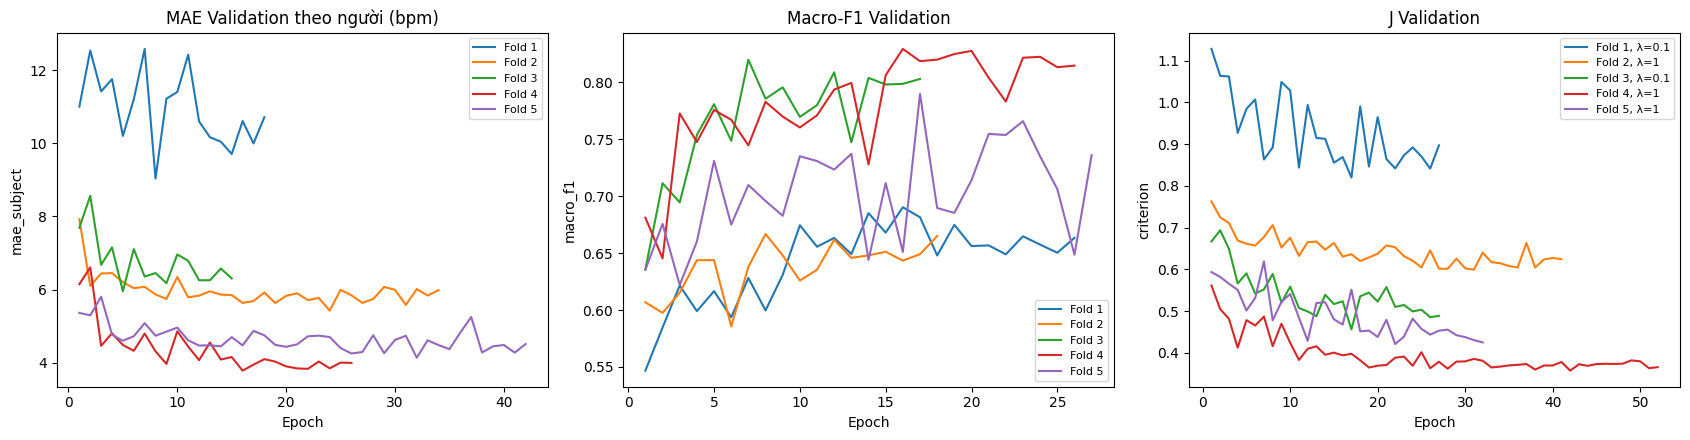

In [ ]:
hr_tables=[]; har_tables=[]; fold_tables=[]
for name,d in [('B0',b0)]+[(m,pred[pred.model==m]) for m in ('B1','B2','M1')]:
    if name!='B2':
        t=d.assign(abs_error=(d.hr_true-d.hr_pred).abs())
        by_subject=t.groupby('subject').abs_error.agg(['mean','count']).reset_index()
        hr_tables.append(dict(model=name,MAE_subject=by_subject['mean'].mean(),SD_subject=by_subject['mean'].std(ddof=1),MAE_pooled=t.abs_error.mean(),windows=len(t)))
        by_subject.to_csv(OUT/f'{name}_subject_MAE.csv',index=False)
        t.groupby('class_true').abs_error.agg(['mean','count']).rename_axis('class_id').to_csv(OUT/f'{name}_activity_MAE.csv')
    if name in ('B2','M1'):
        f1=f1_score(d.class_true,d.class_pred,labels=list(range(8)),average=None,zero_division=0)
        support=np.bincount(d.class_true,minlength=8)
        har_tables.append(dict(model=name,accuracy=accuracy_score(d.class_true,d.class_pred),macro_f1=np.mean(f1)))
        pd.DataFrame({'class_id':range(8),'activity':CLASS_NAMES,'f1':f1,'support':support}).to_csv(OUT/f'{name}_per_class_F1.csv',index=False)
        cm=confusion_matrix(d.class_true,d.class_pred,labels=list(range(8)))
        pd.DataFrame(cm,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(OUT/f'{name}_confusion.csv')
        fig,ax=plt.subplots(figsize=(8,6)); im=ax.imshow(cm);fig.colorbar(im,ax=ax)
        ax.set(xticks=range(8),yticks=range(8),xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,xlabel='Predicted',ylabel='True',title=f'{name} pooled Test')
        plt.setp(ax.get_xticklabels(),rotation=45,ha='right');fig.tight_layout();fig.savefig(OUT/f'{name}_confusion.png',dpi=160);plt.close(fig)
    if name!='B0':
        for fold,g in d.groupby('fold'):
            rec=dict(model=name,fold=fold)
            if name!='B2': rec['mae_subject']=g.assign(err=(g.hr_true-g.hr_pred).abs()).groupby('subject').err.mean().mean()
            if name!='B1':
                rec['macro_f1']=f1_score(g.class_true,g.class_pred,labels=list(range(8)),average='macro',zero_division=0)
                rec['accuracy']=accuracy_score(g.class_true,g.class_pred)
            fold_tables.append(rec)
display(pd.DataFrame(hr_tables));display(pd.DataFrame(har_tables));display(pd.DataFrame(fold_tables).groupby('model').agg(['mean','std']))
pd.DataFrame(hr_tables).to_csv(OUT/'HR_summary.csv',index=False)
pd.DataFrame(har_tables).to_csv(OUT/'HAR_summary.csv',index=False)
pd.DataFrame(fold_tables).to_csv(OUT/'fold_metrics.csv',index=False)
sub1=pd.read_csv(OUT/'B1_subject_MAE.csv').set_index('subject')['mean'];subm=pd.read_csv(OUT/'M1_subject_MAE.csv').set_index('subject')['mean']
pd.DataFrame({'B1':sub1,'M1':subm,'delta_M1_minus_B1':subm-sub1}).to_csv(OUT/'paired_subject_HR.csv')
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
plot_specs=[('B1','mae_subject','MAE Validation theo người (bpm)'),
            ('B2','macro_f1','Macro-F1 Validation'),('M1','criterion','J Validation')]
for ax,(mode,metric,title) in zip(axes,plot_specs):
    for row in selection[selection['mode']==mode].itertuples():
        hist=pd.read_csv(OUT/f'{row.tag}_history.csv')
        ax.plot(hist.epoch,hist[metric],label=f'Fold {row.fold}'+(f', λ={row.lam:g}' if mode=='M1' else ''))
    ax.set(xlabel='Epoch',ylabel=metric,title=title);ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'learning_curves.png',dpi=160);plt.show()


## 8. Tham số và chi phí suy luận

Đo trên mô hình được chọn ở lượt 1, batch 1, `inference_mode`, 50 lần warmup và 500 lần đo có đồng bộ CUDA. B1 + B2 chạy tuần tự. Dung lượng là file `state_dict` gồm trọng số và bộ đệm, không gồm optimizer. Phép đo chỉ bao gồm forward của mạng, không gồm tiền xử lý.


In [ ]:
models={}
for mode in ('B1','B2','M1'):
    row=selection[(selection.fold==1)&(selection['mode']==mode)].iloc[0]
    ck=torch.load(row.path,map_location='cpu',weights_only=False)
    model=CNN(mode).to(DEVICE).eval();model.load_state_dict(ck['state']);models[mode]=model
    torch.save(model.cpu().state_dict(),OUT/f'{mode}_fold1_inference_state.pt');model.to(DEVICE)
x=torch.zeros((1,4,512),device=DEVICE)
def sync():
    if DEVICE.type=='cuda': torch.cuda.synchronize()
def latency(seq):
    with torch.inference_mode():
        for _ in tqdm(range(50),desc="Khởi động",unit="lần",leave=False):
            for model in seq:model(x)
        sync(); times=[]
        for _ in tqdm(range(500),desc="Đo độ trễ",unit="lần",leave=False):
            sync(); st=time.perf_counter()
            for model in seq:model(x)
            sync();times.append((time.perf_counter()-st)*1000)
    return np.median(times),np.percentile(times,95)
resources=[]
for name,seq in tqdm([('B1',[models['B1']]),('B2',[models['B2']]),('M1',[models['M1']]),('B1+B2',[models['B1'],models['B2']])],desc='Đo tài nguyên',unit='cấu hình'):
    med,p95=latency(seq)
    paths=[OUT/f'{m}_fold1_inference_state.pt' for m in (['B1','B2'] if name=='B1+B2' else [name])]
    resources.append(dict(model=name,params=sum(params[m] for m in (['B1','B2'] if name=='B1+B2' else [name])),weights_bytes=sum(p.stat().st_size for p in paths),median_ms=med,p95_ms=p95,device=str(DEVICE)))
display(pd.DataFrame(resources));pd.DataFrame(resources).to_csv(OUT/'resources_fold1.csv',index=False)
print('Hoàn thành:',OUT,'| SMOKE =',SMOKE)


,model,params,weights_bytes,median_ms,p95_ms,device
0,B1,405697,1636817,0.884903,1.656105,cuda
1,B2,406152,1638609,0.851608,1.101639,cuda
2,M1,422665,1706121,1.036064,1.923138,cuda
3,B1+B2,811849,3275426,1.787390,2.910115,cuda


Hoàn thành: /content/drive/MyDrive/M1_results | SMOKE = False


### Nhận xét và giới hạn

M1 đạt MAE **6,657 ± 3,657 bpm**, Accuracy **69,62%** và Macro-F1 **0,7352**. So với B1, MAE tăng 0,122 bpm; so với B2, Macro-F1 tăng 0,00398. M1 giảm **47,94% tham số** so với hai mạng riêng. Kết quả phản ánh đánh đổi giữa chất lượng hai nhiệm vụ và chi phí mô hình.

Đánh giá chỉ áp dụng cho cửa sổ hoạt động thuần nhất. Lọc tiến lùi trên cả bản ghi là xử lý offline; phép đo CUDA không đại diện cho MCU hoặc năng lượng. Thí nghiệm D/E/F được trình bày trong notebook bổ sung M1_PPG_DaLiA_DangMinhTai_DEF_Nop_bai.ipynb.

**Môi trường được lưu:** output cell đầu ghi Tesla T4, PyTorch `2.11.0+cu128`, CUDA `12.8`; `source_environment.json` ghi PyTorch `2.11.0+cu130`, CUDA `13.0`. Hai bản ghi chưa đồng nhất, nên không dùng chúng để khẳng định mọi lần huấn luyện và đo chạy trong cùng một môi trường.


## 9. Đối chiếu phạm vi và tài liệu tham khảo

Cell dưới liệt kê các bước A/B/C đã cài đặt và kiểm tra sự hiện diện của đầu ra. Trạng thái trong bảng phản ánh mã triển khai; kết quả thực nghiệm được chứng minh bằng bảng, hình và CSV đã lưu. D/E/F có notebook và gói kết quả riêng M1_DEF_results.zip.

1. Reiss, A., Indlekofer, I., & Schmidt, P. (2019). *PPG-DaLiA*. UCI Machine Learning Repository. DOI: [10.24432/C53890](https://doi.org/10.24432/C53890).
2. Reiss, A., Indlekofer, I., Schmidt, P., & Van Laerhoven, K. (2019). *Deep PPG: Large-Scale Heart Rate Estimation with Convolutional Neural Networks*. Sensors, 19(14), 3079. DOI: [10.3390/s19143079](https://doi.org/10.3390/s19143079).
3. *PPG Field Study Dataset*, README chính thức, các mục I.2, II và III.3.


In [ ]:
protocol_rows=[
 ('Dữ liệu UCI; README; 15 người','UCI_readme.pdf, source_environment.json, raw_data_audit.csv','đã cài'),
 ('Cửa sổ 8 s/2 s; nhãn HR và HAR thuần nhất','window_audit.csv, preprocess_config.json','đã cài'),
 ('Chia 9/3/3 theo người, 5 lượt','SPLITS trong notebook','đã cài'),
 ('Train-only chuẩn hóa; 8 trọng số lớp','train_only_statistics.json','đã cài'),
 ('B0 đỉnh phổ; B1/B2; M1 và λ 0.1/1/10','B0_predictions.csv, validation_runs.csv, *.pt','đã cài'),
 ('Checkpoint chọn trên Validation trước Test','selected_before_test.json','đã cài'),
 ('MAE theo 15 người, gộp, theo hoạt động; HAR/F1/confusion','HR_summary.csv, HAR_summary.csv, *_confusion.csv','đã cài'),
 ('Đường học và chi phí bộ nhớ/độ trễ','learning_curves.png, resources_fold1.csv','đã cài'),
 ('D: CE có/không trọng số','Notebook D/E/F; DEF/comparison_deltas.csv','notebook bổ sung'),
 ('E: chỉ PPG','Notebook D/E/F; DEF/paired_subject_HR.csv','notebook bổ sung'),
 ('F: ACC-only HAR/Deep PPG','Notebook D/E/F; DEF/HAR_summary.csv','notebook bổ sung'),
]
display(pd.DataFrame(protocol_rows,columns=['Yêu cầu','Chứng cứ dự kiến','Trạng thái mã']))
if SMOKE:
    print('SMOKE=True: kết quả chỉ dùng để kiểm tra pipeline, không đưa vào báo cáo.')
else:
    required=['raw_data_audit.csv','window_audit.csv','train_only_statistics.json','validation_runs.csv',
              'selected_before_test.json','test_predictions.csv','HR_summary.csv','HAR_summary.csv',
              'learning_curves.png','resources_fold1.csv']
    missing=[x for x in required if not (OUT/x).is_file()]
    if missing: raise RuntimeError(f'Chưa hoàn thành phần chính; thiếu: {missing}')
    print('Đã tạo đủ đầu ra phần A/B/C:',OUT)
